![logo](https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/images/notebook-logo.png)

## **Curso**: Residência em Inteligência Artificial
## **Unidade Curricular**: Séries Temporais
## **Professor**: Matheus Vanzan
---

### Setup

* `numpy` (`np`): cálculos numéricos
* `pandas` (`pd`): tabelas (`DataFrame`) e séries (`Series`)
* `matplotlib.pyplot` (`plt`): gráficos
* `statsmodels`: o modelo `ARIMA`
* `itertools`: ferramentas para laços. O `product` gera todas as combinações de $p$, $d$ e $q$ da busca em grade
* `warnings`: o ajuste do `statsmodels` pode emitir avisos sobre os valores iniciais dos parâmetros (`EstimationWarning`) e de convergência (`ConvergenceWarning`) em alguns modelos candidatos da busca em grade. Eles não mudam o resultado desta aula, então silenciamos só esses dois tipos de aviso, e os demais continuam aparecendo
* `PATH`: o endereço base dos dados (um repositório no GitHub). Em cada leitura, somamos a ele o caminho do arquivo

In [1]:
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning

warnings.filterwarnings('ignore', category=EstimationWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)

PATH = 'https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/'

### Série de exemplo

A **produção mensal de uma fábrica** (em milhares de unidades) é uma **série artificial, criada para a aula**, e é a série de exemplo das seções 1 a 5. A função `gerar_producao` gera uma série com:

* uma produção que começa em 100 e **sobe em média 2 por mês** (a tendência)
* uma variação de cada mês que **depende de 0,6 da variação do mês anterior** (a parte autorregressiva)
* um **erro aleatório** em cada mês (desvio-padrão de 1)
* **84 meses**, 7 anos de dados mensais, de janeiro de 2018 a dezembro de 2024

A função gera as variações mês a mês (com um laço `for`) e acumula essas variações com `np.cumsum`. A pergunta de negócio é: **quanto produzir nos próximos 12 meses?**

In [2]:
def gerar_producao(
    n_meses=84,    # 7 anos de dados mensais, de janeiro de 2018 a dezembro de 2024
    inicio=100,    # produção do primeiro mês, em milhares de unidades
    deriva=2.0,    # crescimento médio por mês
    phi=0.6,       # peso da variação do mês anterior
    sigma=1.0,     # desvio-padrão do erro aleatório
    seed=7,        # semente do gerador aleatório: deixa os números sempre iguais
):
    rng = np.random.default_rng(seed)
    desvio = 0.0
    variacoes = []
    for mes in range(n_meses):
        # desvio em relação ao crescimento médio: phi vezes o do mês anterior mais um erro aleatório
        desvio = phi * desvio + rng.normal(0, sigma)
        variacoes.append(deriva + desvio)
    return pd.Series(
        inicio + np.cumsum(variacoes),
        index=pd.date_range('2018-01-01', periods=n_meses, freq='MS'),
    )

A série, com os valores padrão da função:

In [3]:
producao = gerar_producao()
producao.head()

,0
2018-01-01,102.001230
2018-02-01,104.300714
2018-03-01,106.206266
2018-04-01,107.259006
2018-05-01,108.235979


## 📌 1 - Diferenciação

### 1.1 - Diferenciação

Os modelos AR e MA (Aula 3) supõem uma série **estacionária**, com média e variância constantes ao longo do tempo. Uma série com tendência não é estacionária, porque a média muda. A **diferenciação** resolve isso: ela troca cada valor pela **variação** em relação ao valor anterior,

$$\Delta x_t = x_t - x_{t-1}$$

Ela não suaviza a série nem apaga pontos, só troca valor por variação. O método `.diff()` faz essa conta em todos os pontos (o argumento `periods=1` é o padrão). O **primeiro ponto fica sem valor** (`NaN`), porque não tem ponto anterior, e o `.dropna()` remove esse ponto. Aplicando na produção da série de exemplo:

In [13]:
producao_dif = producao.diff().dropna()
producao_dif.head()

,0
2018-02-01,2.299484
2018-03-01,1.905552
2018-04-01,1.052740
2018-05-01,0.976973
2018-06-01,0.394537


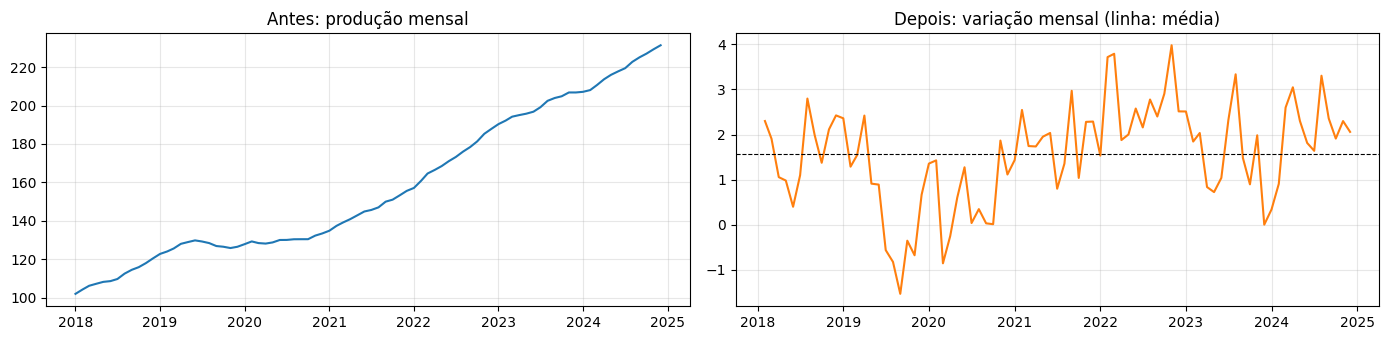

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 3.5))
eixos[0].plot(producao.index, producao.values)
eixos[0].set_title('Antes: produção mensal')
eixos[1].plot(producao_dif.index, producao_dif.values, color='tab:orange')
eixos[1].axhline(producao_dif.mean(), color='black', linewidth=0.8, linestyle='--')
eixos[1].set_title('Depois: variação mensal (linha: média)')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A produção **sobe** ao longo dos 84 meses: a média **não é constante**. Depois de diferenciar, a variação mensal oscila em torno de uma média constante. A série diferenciada pode ser modelada com AR e MA.

### 1.2 - Integração

A **integração** é o caminho de volta: da variação ao valor, **somando**,

$$x_t = x_{t-1} + \Delta x_t$$

O método `.cumsum()` calcula a **soma acumulada**: cada linha recebe a soma dela com todas as anteriores. Somando as variações mensais ao primeiro valor da produção, recuperamos a série:

In [15]:
recuperada = producao.iloc[0] + producao_dif.cumsum()

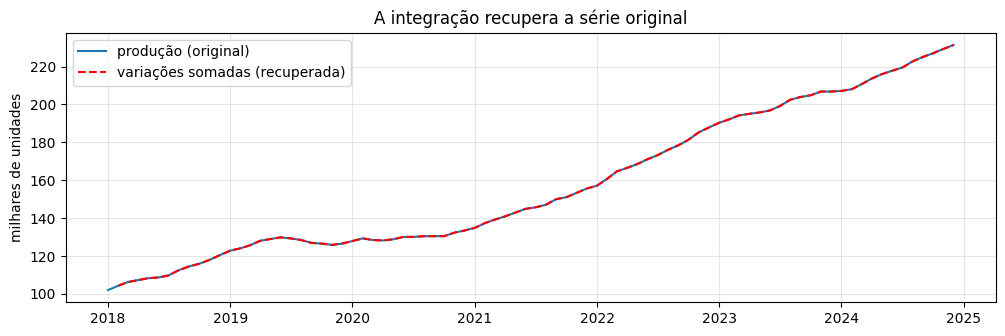

In [16]:
plt.figure(figsize=(12, 3.5))
plt.plot(producao.index, producao.values, color='tab:blue', label='produção (original)')
plt.plot(recuperada.index, recuperada.values, color='red', linestyle='--', label='variações somadas (recuperada)')
plt.title('A integração recupera a série original')
plt.ylabel('milhares de unidades')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

As duas linhas coincidem. É exatamente isso que o ARIMA faz com a previsão: ele prevê as **variações** e as soma ao último valor observado para voltar à escala original (item 5.1).

## 📌 2 - Modelo ARIMA

O **ARIMA** (*AutoRegressive Integrated Moving Average*) reúne três partes:

* **AR** (autorregressivo): depende dos valores passados da própria série (Aula 3)
* **I** (integrado): a diferenciação que torna a série estacionária (item 1)
* **MA** (média móvel): depende dos erros passados do modelo (Aula 3)

Ou seja, ARIMA é o ARMA da aula passada com uma etapa de diferenciação antes e a integração depois.

### 2.1 - Os parâmetros p, d e q

O modelo se escreve **ARIMA($p$, $d$, $q$)**:

* $p$: quantos valores passados da série entram (parte AR)
* $d$: quantas vezes a série é diferenciada (parte I)
* $q$: quantos erros passados entram (parte MA)

Em geral, os valores são pequenos: 0, 1 ou 2. A equação aplica o ARMA à série diferenciada $w_t = \Delta^d x_t$:

$$w_t = c + \varphi_1 w_{t-1} + \dots + \varphi_p w_{t-p} + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q} + \varepsilon_t$$

Os $\varphi$ são os pesos dos valores passados (AR), os $\theta$ são os pesos dos erros passados (MA), $\varepsilon_t$ é o erro do mês $t$ e $c$ é uma constante.

Para ver o papel do $d$ na série de exemplo, comparamos a produção sem diferenciar ($d = 0$), diferenciada uma vez ($d = 1$) e duas vezes ($d = 2$):

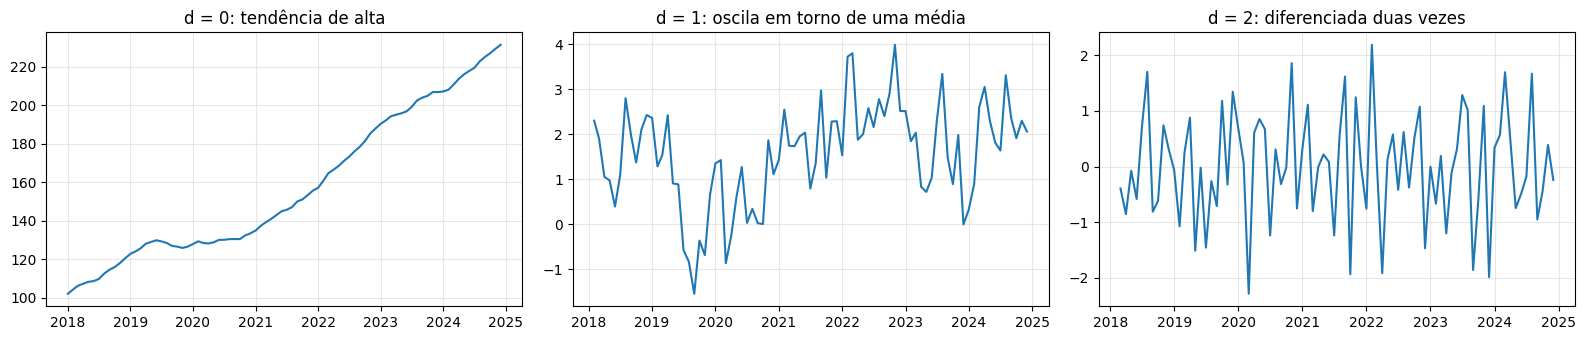

In [19]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 3.5))
for eixo, serie, titulo in zip(eixos, [producao, producao.diff(), producao.diff().diff()], ['d = 0: tendência de alta', 'd = 1: oscila em torno de uma média', 'd = 2: diferenciada duas vezes']):
    eixo.plot(serie)
    eixo.set_title(titulo)
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Com $d = 0$ a produção tem tendência de alta e a média muda com o tempo. Com $d = 1$ a série oscila em torno de uma média, e com $d = 2$ ela é diferenciada duas vezes. Qual $d$ funciona melhor para prever é uma pergunta de avaliação, e a resposta vem do item 3.

### 2.2 - Casos particulares

Alguns valores de $p$, $d$ e $q$ dão modelos conhecidos:

* **ARIMA(0, 1, 0):** só diferencia, **sem constante**. O próximo valor é o último mais um erro, a previsão **ingênua** (Naive) da Aula 2, que repete o último valor. É o nosso **baseline**
* **ARIMA(1, 0, 0):** com $d = 0$ é um AR(1), para série já estacionária
* **ARIMA(0, 0, 1):** com $d = 0$ é um MA(1)
* **ARIMA(1, 1, 0):** as variações da produção seguem um AR(1), o modelo do nosso exemplo

Vamos ajustar quatro desses casos na produção da série de exemplo, com os mesmos passos: criar o **modelo**, **ajustar** (`.fit()`) e **prever** (`.forecast()`).

#### 2.2.1 - ARIMA(0, 1, 0)

O `ARIMA(...)` do `statsmodels` é uma **classe**, como o `STL` da Aula 2. Ele cria o **modelo**: guarda a configuração (a série e a ordem $(p, d, q)$), mas ainda não tem parâmetros:

In [20]:
modelo_010 = ARIMA(
   producao,

   order = (0, 1, 0) # (p, d, q)
)

O `.fit()` faz o **ajuste**: estima os parâmetros a partir da série e devolve o modelo ajustado.

In [22]:
ajuste_010 = modelo_010.fit()

Os parâmetros estimados ficam em `.params`: `const` é a constante $c$, `ar.L1` é o peso $\varphi_1$, `ma.L1` é o peso $\theta_1$, `x1` é a deriva (com `trend="t"`) e `sigma2` é a variância do erro. O ARIMA(0, 1, 0) só estima a variância do erro:

In [23]:
print(ajuste_010.params.round(2))

sigma2    3.68
dtype: float64


O ajuste guarda a **curva de ajuste** em `.fittedvalues`: a previsão de 1 passo de cada mês, em que o modelo usa o valor do mês anterior e prevê o mês seguinte. O primeiro mês não tem mês anterior, e o `statsmodels` preenche o valor inicial de forma artificial, então o descartamos com `.iloc[1:]`. À esquerda, a curva de ajuste do ARIMA(0, 1, 0) contra a produção. À direita, a **dispersão**: cada ponto é um mês, com o valor real no eixo x e o ajustado no eixo y, e a linha pontilhada é a diagonal (ajuste perfeito). Quanto mais perto da diagonal, melhor o ajuste:

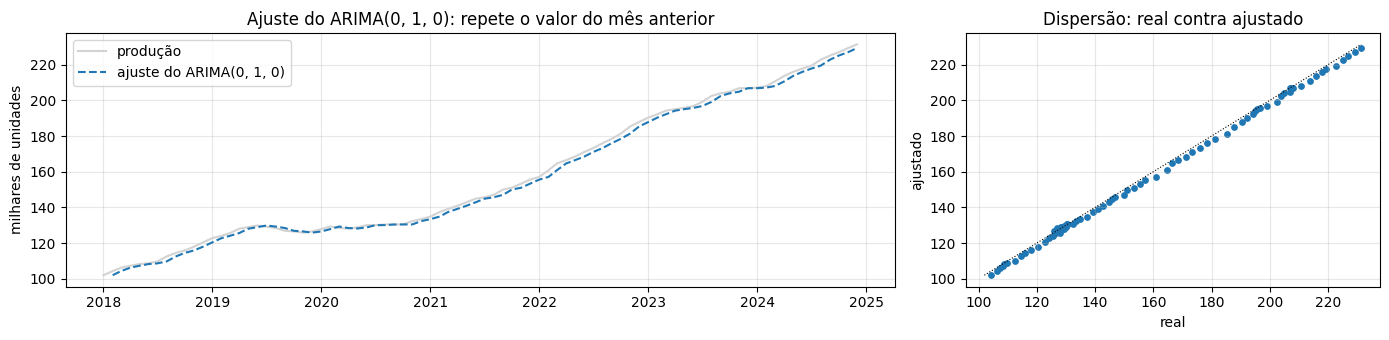

In [24]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={'width_ratios': [2, 1]})
eixos[0].plot(producao.index, producao.values, color='lightgray', label='produção')
eixos[0].plot(ajuste_010.fittedvalues.index[1:], ajuste_010.fittedvalues.values[1:], color='tab:blue', linestyle='--', label='ajuste do ARIMA(0, 1, 0)')
eixos[0].set_title('Ajuste do ARIMA(0, 1, 0): repete o valor do mês anterior')
eixos[0].set_ylabel('milhares de unidades')
eixos[0].legend()
eixos[1].scatter(producao.values[1:], ajuste_010.fittedvalues.values[1:], color='tab:blue', s=15)
eixos[1].plot([producao.min(), producao.max()], [producao.min(), producao.max()], color='black', linewidth=0.8, linestyle=':')
eixos[1].set_title('Dispersão: real contra ajustado')
eixos[1].set_xlabel('real')
eixos[1].set_ylabel('ajustado')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Falta **prever**. O `.forecast(h)` usa o modelo **ajustado** para prever os $h$ meses seguintes ao fim da série, aqui os 12 meses de 2025. O $h$ é o **horizonte** de previsão, e a previsão do ARIMA(0, 1, 0) repete o último valor:

In [25]:
h = 12    # horizonte: 12 meses à frente (um ano)

In [26]:
previsao_010 = ajuste_010.forecast(h)

In [27]:
previsao_010.round(1)

,predicted_mean
2025-01-01,231.4
2025-02-01,231.4
2025-03-01,231.4
2025-04-01,231.4
2025-05-01,231.4
2025-06-01,231.4
2025-07-01,231.4
2025-08-01,231.4
2025-09-01,231.4
2025-10-01,231.4


#### 2.2.2 - ARIMA(1, 0, 0)

O mesmo caminho: criar o modelo, ajustar e olhar a curva de ajuste. Sem diferenciação, o AR(1) também usa o valor do mês anterior, com um peso próximo de 1, então a curva de ajuste fica quase igual à do caso anterior. A diferença aparece na previsão, mais adiante:

In [28]:
modelo_100 = ARIMA(
    # série de ajuste
    producao,

    # ordem (p, d, q): um AR(1), sem diferenciação
    order=(1, 0, 0),
)

In [29]:
ajuste_100 = modelo_100.fit()

In [34]:
print(ajuste_100.params)

const     164.140229
ar.L1       0.999590
sigma2      3.682383
dtype: float64


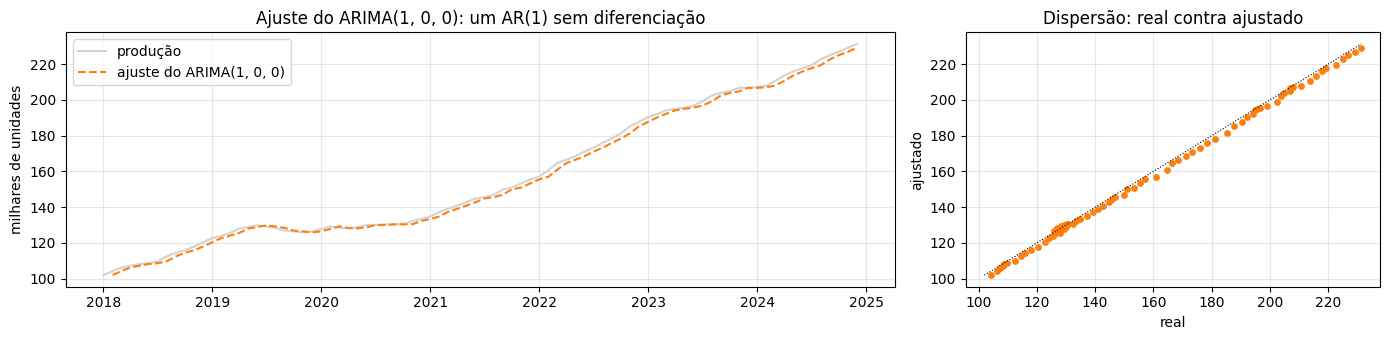

In [31]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={'width_ratios': [2, 1]})
eixos[0].plot(producao.index, producao.values, color='lightgray', label='produção')
eixos[0].plot(ajuste_100.fittedvalues.index[1:], ajuste_100.fittedvalues.values[1:], color='tab:orange', linestyle='--', label='ajuste do ARIMA(1, 0, 0)')
eixos[0].set_title('Ajuste do ARIMA(1, 0, 0): um AR(1) sem diferenciação')
eixos[0].set_ylabel('milhares de unidades')
eixos[0].legend()
eixos[1].scatter(producao.values[1:], ajuste_100.fittedvalues.values[1:], color='tab:orange', s=15)
eixos[1].plot([producao.min(), producao.max()], [producao.min(), producao.max()], color='black', linewidth=0.8, linestyle=':')
eixos[1].set_title('Dispersão: real contra ajustado')
eixos[1].set_xlabel('real')
eixos[1].set_ylabel('ajustado')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

E a previsão dos próximos 12 meses:

In [33]:
previsao_100 = ajuste_100.forecast(h)
previsao_100

,predicted_mean
2025-01-01,231.353809
2025-02-01,231.326253
2025-03-01,231.298708
2025-04-01,231.271174
2025-05-01,231.243652
2025-06-01,231.216141
2025-07-01,231.188641
2025-08-01,231.161153
2025-09-01,231.133675
2025-10-01,231.106209


#### 2.2.3 - ARIMA(0, 0, 1)

O MA(1): sem diferenciação, o valor depende do erro do mês anterior. Criamos o modelo, ajustamos e olhamos a curva de ajuste:

In [35]:
modelo_001 = ARIMA(
    # série de ajuste
    producao,

    # ordem (p, d, q): um MA(1), sem diferenciação
    order=(0, 0, 1),
)

In [36]:
ajuste_001 = modelo_001.fit()

In [37]:
print(ajuste_001.params.round(2))

const     157.71
ma.L1       1.00
sigma2    372.99
dtype: float64


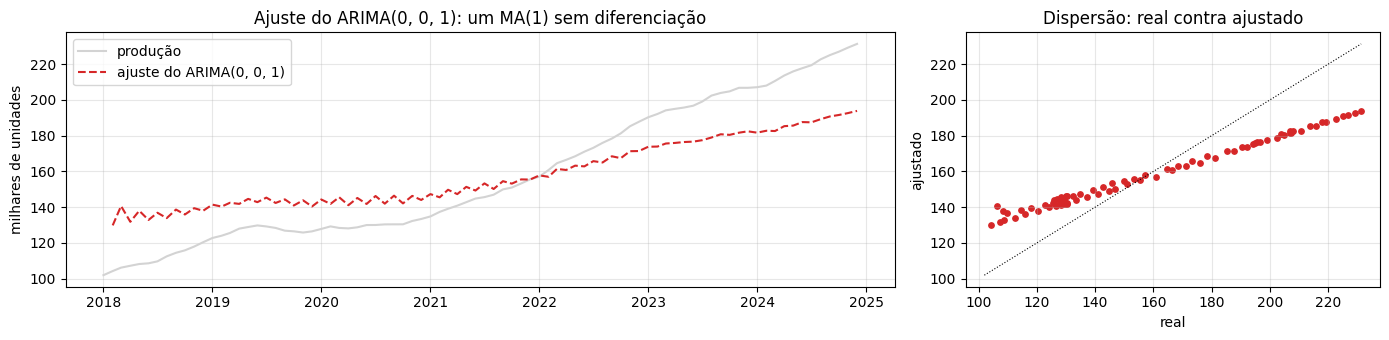

In [38]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={'width_ratios': [2, 1]})
eixos[0].plot(producao.index, producao.values, color='lightgray', label='produção')
eixos[0].plot(ajuste_001.fittedvalues.index[1:], ajuste_001.fittedvalues.values[1:], color='tab:red', linestyle='--', label='ajuste do ARIMA(0, 0, 1)')
eixos[0].set_title('Ajuste do ARIMA(0, 0, 1): um MA(1) sem diferenciação')
eixos[0].set_ylabel('milhares de unidades')
eixos[0].legend()
eixos[1].scatter(producao.values[1:], ajuste_001.fittedvalues.values[1:], color='tab:red', s=15)
eixos[1].plot([producao.min(), producao.max()], [producao.min(), producao.max()], color='black', linewidth=0.8, linestyle=':')
eixos[1].set_title('Dispersão: real contra ajustado')
eixos[1].set_xlabel('real')
eixos[1].set_ylabel('ajustado')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

O MA(1) sem diferenciação **não acompanha a tendência**: o ajuste fica abaixo da produção nos meses finais, e a variância do erro estimada (`sigma2`) é bem maior que a dos outros casos. O $c$ é a média da série.

E a previsão dos próximos 12 meses:

In [39]:
previsao_001 = ajuste_001.forecast(h)

#### 2.2.4 - ARIMA(1, 1, 0)

Há um detalhe do `statsmodels`: com $d \geq 1$ o ARIMA **não tem constante por padrão**, porque ela some na diferenciação. A produção sobe em média 2 por mês, e essa subida (a **deriva**) entra no modelo com `trend='t'`:

In [40]:
modelo_110 = ARIMA(
    # série de ajuste
    producao,

    # ordem (p, d, q): um AR(1) sobre a série diferenciada uma vez
    order=(1, 1, 0),

    # tendência: 'n' (sem deriva, padrão) ou 't' (deriva: a variação média por mês)
    trend='t',
)

In [41]:
ajuste_110 = modelo_110.fit()

In [42]:
print(ajuste_110.params.round(2))

x1        1.58
ar.L1     0.62
sigma2    0.76
dtype: float64


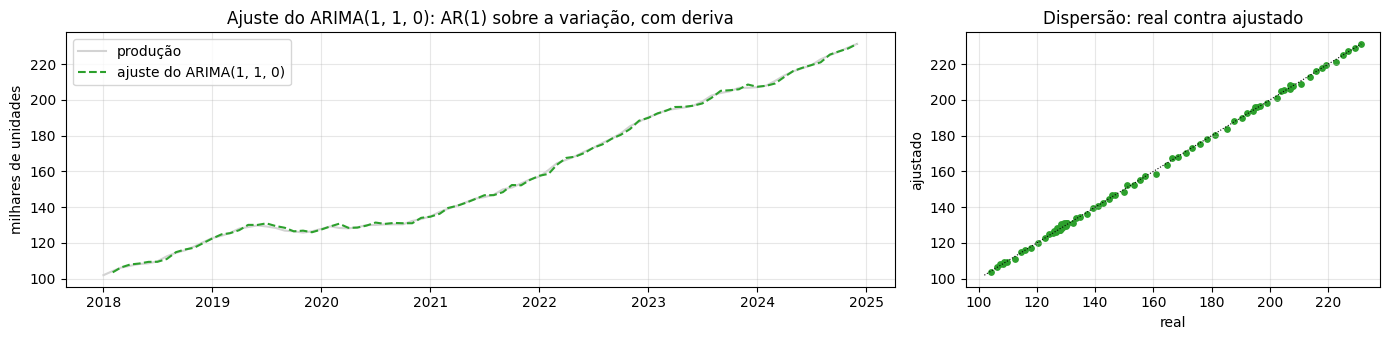

In [43]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={'width_ratios': [2, 1]})
eixos[0].plot(producao.index, producao.values, color='lightgray', label='produção')
eixos[0].plot(ajuste_110.fittedvalues.index[1:], ajuste_110.fittedvalues.values[1:], color='tab:green', linestyle='--', label='ajuste do ARIMA(1, 1, 0)')
eixos[0].set_title('Ajuste do ARIMA(1, 1, 0): AR(1) sobre a variação, com deriva')
eixos[0].set_ylabel('milhares de unidades')
eixos[0].legend()
eixos[1].scatter(producao.values[1:], ajuste_110.fittedvalues.values[1:], color='tab:green', s=15)
eixos[1].plot([producao.min(), producao.max()], [producao.min(), producao.max()], color='black', linewidth=0.8, linestyle=':')
eixos[1].set_title('Dispersão: real contra ajustado')
eixos[1].set_xlabel('real')
eixos[1].set_ylabel('ajustado')
for eixo in eixos:
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

E a previsão dos próximos 12 meses:

In [44]:
previsao_110 = ajuste_110.forecast(h)

#### 2.2.5 - Comparando as previsões

No mesmo gráfico, a projeção dos quatro casos:

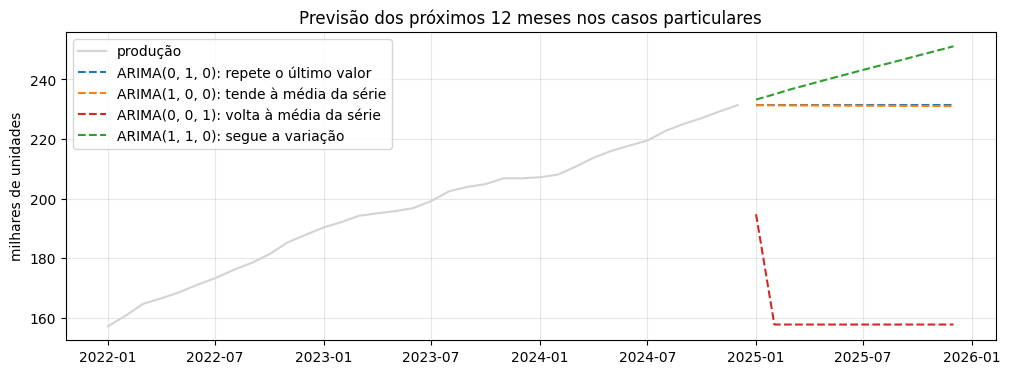

In [45]:
plt.figure(figsize=(12, 4))
plt.plot(producao.index[-36:], producao.values[-36:], color='lightgray', label='produção')
plt.plot(previsao_010.index, previsao_010.values, color='tab:blue', linestyle='--', label='ARIMA(0, 1, 0): repete o último valor')
plt.plot(previsao_100.index, previsao_100.values, color='tab:orange', linestyle='--', label='ARIMA(1, 0, 0): tende à média da série')
plt.plot(previsao_001.index, previsao_001.values, color='tab:red', linestyle='--', label='ARIMA(0, 0, 1): volta à média da série')
plt.plot(previsao_110.index, previsao_110.values, color='tab:green', linestyle='--', label='ARIMA(1, 1, 0): segue a variação')
plt.title('Previsão dos próximos 12 meses nos casos particulares')
plt.ylabel('milhares de unidades')
plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.show()

O ARIMA(0, 1, 0) é uma linha reta no último valor. O AR(1) sem diferenciação tem $\varphi$ próximo de 1 e quase repete o último valor, caminhando devagar para a média da série. O MA(1) sem diferenciação cai para a média da série (o $c$ estimado) logo nos primeiros meses e fica nela: a média ignora a tendência, e o nível atual é bem maior. O ARIMA(1, 1, 0) parte do último valor e continua com a variação média da série. Qual deles prevê melhor é a pergunta do item 3.

## 📌 3 - Avaliação e escolha do modelo

Há vários ARIMA($p$, $d$, $q$) possíveis, e o erro no treino não diz qual escolher: o modelo mais complexo tende a ajustar melhor o treino, mas pode apenas seguir o **ruído** (o **sobreajuste**). Quem prevê melhor aparece em dados que o modelo **não viu**. Este item mostra duas estratégias de escolha e depois as compara:

1. **Validação temporal:** o treino ajusta cada candidato, a validação compara o erro (MAE ou RMSE, da Aula 2) e escolhe, e o teste mede o resultado final
2. **AIC e BIC:** calculados nos dados do ajuste, sem partição de validação, medem o ajuste com penalização pela complexidade

### 3.1 - Baseline

Dividimos a série em três partes, **em ordem no tempo**: 60 meses de **treino** (ajusta cada candidato), 12 de **validação** (escolhe) e 12 de **teste** (resultado final, **uma única vez**). O `treino_val` junta treino e validação, os 72 primeiros meses:

In [46]:
producao.head()

,0
2018-01-01,102.001230
2018-02-01,104.300714
2018-03-01,106.206266
2018-04-01,107.259006
2018-05-01,108.235979


In [47]:
h

12

In [48]:
treino = producao.iloc[:-2*h]
validacao = producao.iloc[-2*h:-h]
teste = producao.iloc[-h:]


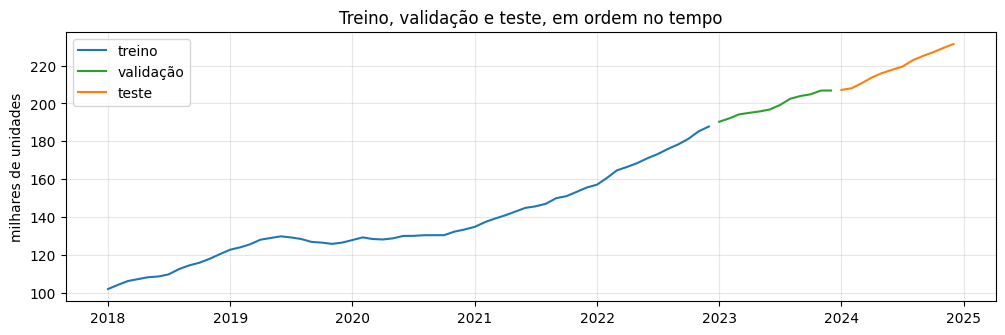

In [49]:
plt.figure(figsize=(12, 3.5))

plt.plot(treino.index, treino.values, color='tab:blue', label='treino')
plt.plot(validacao.index, validacao.values, color='tab:green', label='validação')
plt.plot(teste.index, teste.values, color='tab:orange', label='teste')

plt.title('Treino, validação e teste, em ordem no tempo')
plt.ylabel('milhares de unidades')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

O **baseline** é a régua: um ARIMA só vale a pena se tiver erro **menor** que ele, nas mesmas métricas e nos mesmos dados. É o Naive (o ARIMA(0, 1, 0) sem constante), que repete o último valor do treino nos 12 meses da validação. A métrica é definida **antes** de olhar os resultados: aqui, o **MAE**.

In [51]:
naive_val = pd.Series(treino.iloc[-1], index=validacao.index)

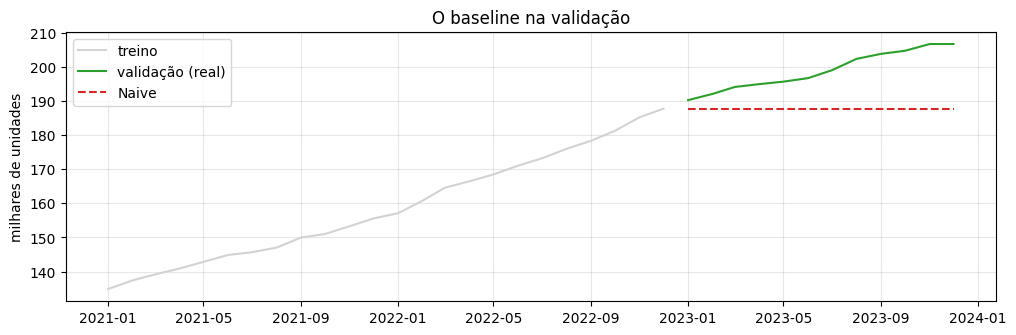

In [52]:
plt.figure(figsize=(12, 3.5))
plt.plot(treino.index[-24:], treino.values[-24:], color='lightgray', label='treino')
plt.plot(validacao.index, validacao.values, color='tab:green', label='validação (real)')
plt.plot(naive_val.index, naive_val.values, color='tab:red', linestyle='--', label='Naive')
plt.title('O baseline na validação')
plt.ylabel('milhares de unidades')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [53]:
erro_naive_val = validacao - naive_val
mae_naive_val = erro_naive_val.abs().mean()

print('Naive na validação | MAE:', round(mae_naive_val, 2), '| RMSE:', round(np.sqrt((erro_naive_val ** 2).mean()), 2))

Naive na validação | MAE: 11.2 | RMSE: 12.5


### 3.2 - Grid Search

Para escolher $p$, $d$ e $q$, ajustamos **todas as combinações** de uma grade pequena (de 0 a 2 em cada um, 27 modelos) e medimos o erro de cada uma. É a **busca em grade** (*grid search*), a forma básica de **ajustar hiperparâmetros** (aqui, $p$, $d$ e $q$). A função `auto_arima`, da biblioteca `pmdarima`, faz isso sozinha, mas aqui usamos um laço simples, porque o `pmdarima` nem sempre vem instalado no Colab. O `itertools.product(range(3), range(3), range(3))` gera os 27 trios $(p, d, q)$ em um único laço `for`: cada candidato é ajustado no **treino**, prevê a **validação**, e o MAE e o RMSE viram uma linha do `DataFrame`:

In [58]:
# A tendência muda conforme o d, porque a série diferenciada se comporta de outro jeito:
#   d = 0: 'c', a série oscila em torno de uma média constante
#   d = 1: 't', a série diferenciada tem média diferente de zero (a deriva)
#   d = 2: 'n', depois de duas diferenciações não sobra tendência

tendencia = {0: 'c', 1: 't', 2: 'n'}

In [57]:
itertools.product(range(3), range(3), range(3))

In [66]:
linhas_validacao = []

for p, d, q in itertools.product(range(3), range(3), range(3)):
    # print(p, d, q)

    model_v = ARIMA(
        treino,
        order = (p, d, q),
        trend = tendencia[d]
    )
    ajuste_v = model_v.fit()
    erro_v = validacao - ajuste_v.forecast(h)

    linhas_validacao.append({
        'ordem': f'ARIMA({p},{d},{q})',
        'p':p, 'd':d, 'q':q,
        'MAE': erro_v.abs().mean(),
        'RMSE': np.sqrt((erro_v**2).mean())
    })

In [69]:
linhas_validacao[7]

{'ordem': 'ARIMA(0,2,1)',
 'p': 0,
 'd': 2,
 'q': 1,
 'MAE': np.float64(7.810506467320799),
 'RMSE': np.float64(9.106088586932602)}

In [71]:
grade_validacao = pd.DataFrame(linhas_validacao).sort_values('MAE')
grade_validacao.head(10)

,ordem,p,d,q,MAE,RMSE
12,"ARIMA(1,1,0)",1,1,0,0.718781,0.887696
22,"ARIMA(2,1,1)",2,1,1,0.727684,0.837902
21,"ARIMA(2,1,0)",2,1,0,1.283984,1.605030
5,"ARIMA(0,1,2)",0,1,2,1.628526,1.857528
4,"ARIMA(0,1,1)",0,1,1,1.701171,1.923558
3,"ARIMA(0,1,0)",0,1,0,1.747221,1.968297
20,"ARIMA(2,0,2)",2,0,2,2.378954,2.736162
19,"ARIMA(2,0,1)",2,0,1,2.846242,3.182087
13,"ARIMA(1,1,1)",1,1,1,2.910643,3.327269
14,"ARIMA(1,1,2)",1,1,2,3.372934,3.934297


A tabela mostra os 8 candidatos com menor MAE na validação, com o RMSE ao lado:

In [82]:
grade_validacao.set_index('ordem')[['MAE', 'RMSE']].sort_values(['MAE'])

,MAE,RMSE
ordem,,
"ARIMA(1,1,0)",0.718781,0.887696
"ARIMA(2,1,1)",0.727684,0.837902
"ARIMA(2,1,0)",1.283984,1.605030
"ARIMA(0,1,2)",1.628526,1.857528
"ARIMA(0,1,1)",1.701171,1.923558
"ARIMA(0,1,0)",1.747221,1.968297
"ARIMA(2,0,2)",2.378954,2.736162
"ARIMA(2,0,1)",2.846242,3.182087
"ARIMA(1,1,1)",2.910643,3.327269


A regra de escolha tem três partes: vence o **menor MAE**; se o erro for **parecido** (até 10% acima do menor), fica o modelo **mais simples** (menos parâmetros e menos diferenciações, $p + d + q$); e o escolhido precisa ter MAE **menor que o do baseline**.

> **Qual métrica usar:** a métrica é definida **antes** de olhar os resultados, pelo **custo do erro** no problema. O **MAE** trata todos os erros com o mesmo peso e mede o erro típico: serve quando errar 10 custa o dobro de errar 5 (vendas diárias de uma padaria). O **RMSE** pesa mais os erros grandes: serve quando um erro grande custa muito mais que vários pequenos (errar o pico de demanda de energia de uma fábrica e causar um apagão). Aqui, errar a produção em 10 mil unidades custa o dobro de errar em 5 mil, então usamos o **MAE**. O RMSE aparece na tabela só para comparação: se os dois escolherem o mesmo modelo, a escolha é segura.

Passo 1: o menor MAE da grade e o limite de 10% acima dele.

Passo 2: os candidatos com erro parecido são os que têm MAE até esse limite.

Passo 3: a complexidade de cada candidato é a soma $p + d + q$.

Passo 4: o escolhido é o de menor complexidade (no empate, o de menor MAE).

Passo 5: a ordem escolhida vira a tupla $(p, d, q)$ usada nos próximos ajustes.

O MAE do baseline na validação é 11,20. O menor MAE é do ARIMA(1, 1, 0), com 0,72, e só o ARIMA(2, 1, 1) fica até 10% acima (0,73). Fica o **mais simples**, o **ARIMA(1, 1, 0)**, com MAE bem abaixo dos 11,20 do Naive.

O **teste** mede o resultado final, **uma única vez**. O modelo escolhido é reajustado com o treino mais a validação (`treino_val`), e a previsão dos 12 meses do teste é comparada com a do baseline:

No teste, o ARIMA(1, 1, 0) erra 4,90 (MAE) e 5,81 (RMSE), contra 12,22 e 14,54 do Naive: **ganha do baseline**. O teste foi usado uma única vez, só para confirmar a escolha.

### 3.3 - AIC e BIC

A segunda estratégia seleciona **sem partição de validação**. O **AIC** e o **BIC** usam só os dados do ajuste (aqui, os 72 meses de `treino_val`) e deixam o teste reservado. Eles medem o **ajuste com penalização**, e não o erro de previsão:

$$AIC = 2k - 2 \ln L \qquad BIC = k \ln n - 2 \ln L$$

Aqui, $k$ é o número de parâmetros e $n$ é o número de observações. O termo $-2 \ln L$ é a **falta de ajuste** (não é erro como o MAE ou o RMSE): ele **cai** quando entram mais parâmetros. O termo $2k$ (no AIC) e $k \ln n$ (no BIC) é o **custo** da complexidade, e o BIC cobra mais por parâmetro, por isso prefere modelos mais simples. **O menor valor vence**, e só vale comparar modelos da **mesma série** e com o **mesmo $d$** (a diferenciação muda os dados sobre os quais a verossimilhança é calculada).

> Não precisamos calcular essas fórmulas à mão. O `ARIMA` do `statsmodels` calcula o AIC e o BIC **automaticamente** quando ajusta o modelo e os guarda em `.aic` e `.bic`. Ajustando o ARIMA(1, 1, 0) em `treino_val`:

In [84]:
treino_val = producao.iloc[:-h]

In [85]:
ajuste = ARIMA(treino_val, order=(1, 1, 0), trend='t').fit()

In [86]:
ajuste.aic

np.float64(191.9929592587995)

In [87]:
ajuste.bic

np.float64(198.78099888992344)

In [90]:
print(dir(ajuste))

['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_apply', '_cache', '_cov_approx_centered', '_cov_approx_complex_step', '_cov_params_approx', '_cov_params_oim', '_cov_params_opg', '_cov_params_robust_approx', '_cov_params_robust_oim', '_data_attr', '_data_attr_model', '_data_in_cache', '_fixed_params', '_fixed_params_index', '_free_params_index', '_get_previous_updated', '_get_robustcov_results', '_get_wald_nonlinear', '_has_fixed_params', '_init_kwds', '_news_previous_data', '_news_previous_results', '_news_updated_data', '_news_updated_results', '_params_ar', '_params_exog', '_params_ma', '_params_seasonal_ar', '_params_seasonal_ma',

Com a mesma grade, ajustamos cada candidato em `treino_val` e lemos o `.aic` e o `.bic` do ajuste, sem prever nada.

In [91]:
linhas_ic = []

for p, d, q in itertools.product(range(3), range(3), range(3)):
    ajuste_ic = ARIMA(treino_val, order=(p, d, q), trend=tendencia[d]).fit()
    linhas_ic.append({
        'ordem': 'ARIMA' + str((p, d, q)),
        'p': p,
        'd': d,
        'q': q,
        'AIC': ajuste_ic.aic,
        'BIC': ajuste_ic.bic,
    })

In [96]:
grade_ic = pd.DataFrame(linhas_ic)
grade_ic.sort_values(['AIC'])

,ordem,p,d,q,AIC,BIC
8,"ARIMA(0, 2, 2)",0,2,2,190.468012,197.213497
16,"ARIMA(1, 2, 1)",1,2,1,191.266437,198.011923
12,"ARIMA(1, 1, 0)",1,1,0,191.992959,198.780999
17,"ARIMA(1, 2, 2)",1,2,2,192.230037,201.224018
24,"ARIMA(2, 2, 0)",2,2,0,192.322043,199.067528
7,"ARIMA(0, 2, 1)",0,2,1,192.451678,196.948669
13,"ARIMA(1, 1, 1)",1,1,1,192.934918,201.985638
25,"ARIMA(2, 2, 1)",2,2,1,193.076118,202.070099
14,"ARIMA(1, 1, 2)",1,1,2,193.234282,204.547681
21,"ARIMA(2, 1, 0)",2,1,0,193.489921,202.540640


Como o AIC e o BIC só se comparam entre modelos com o **mesmo $d$**, usamos o $d$ escolhido pela validação (`ordem_val`) e deixamos o AIC e o BIC escolherem só $p$ e $q$:

Com $d = 1$, o AIC e o BIC apontam o mesmo modelo da validação, o **ARIMA(1, 1, 0)** (AIC de 192,0 e BIC de 198,8). Cada critério escolhe **um único candidato antes do teste**.

### 3.4 - Comparativo

Para comparar as duas estratégias, medimos no **teste** o modelo que a validação escolheu e o que o AIC e o BIC escolheram, todos ajustados em `treino_val`, ao lado do baseline:

In [102]:
ordem_val = (1, 1, 0)

In [103]:
naive = pd.Series(treino_val.iloc[-1], index=teste.index)
erro_teste_naive = teste - naive

In [104]:
linhas_teste = [
    {
        'modelo': 'Baseline: Naive',
        'MAE': erro_teste_naive.abs().mean(),
        'RMSE': np.sqrt((erro_teste_naive ** 2).mean()),
    },
    {
        'modelo': 'Validação: ARIMA' + str(ordem_val),
        'MAE': erro_teste_val.abs().mean(),
        'RMSE': np.sqrt((erro_teste_val ** 2).mean()),
    },
]

NameError: name 'erro_teste_val' is not defined

In [3]:
for criterio, linha in [('AIC', linha_aic), ('BIC', linha_bic)]:
    ordem = (int(linha['p']), int(linha['d']), int(linha['q']))
    erro_t = teste - ARIMA(treino_val, order=ordem, trend=tendencia[ordem[1]]).fit().forecast(h)
    linhas_teste.append({
        'modelo': criterio + ': ARIMA' + str(ordem),
        'MAE': erro_t.abs().mean(),
        'RMSE': np.sqrt((erro_t ** 2).mean()),
    })

In [3]:
tabela_teste = pd.DataFrame(linhas_teste).set_index('modelo')

In [3]:
tabela_teste.round(2)

Nesta série as três escolhas coincidem: o ARIMA(1, 1, 0) é o escolhido pela validação, pelo AIC e pelo BIC, com MAE de 4,90 no teste, contra 12,22 do Naive. Nem sempre é assim: o AIC menor **não garante** o menor erro no teste, e as estratégias podem apontar modelos diferentes (como no Momento de praticar).

> **Cuidados na escolha:** o AIC menor **não garante** o menor erro futuro; a métrica calculada na **série inteira é otimista**, porque o modelo já viu esses dados; testar combinações demais vira **pescaria** (alguma parece boa por acaso, e só serve para aquele trecho); e escolher pelo teste faz o teste **participar da escolha**, por isso a escolha fica na validação e o teste só confirma. Com dados suficientes, reserve também uma validação separada. O **resíduo** do modelo escolhido ainda precisa ser conferido (item 4).

## 📌 4 - Diagnóstico dos resíduos

Se o modelo capturou a estrutura da série, o **resíduo** deve parecer **ruído**: sem tendência, sem padrão e sem autocorrelação. Um resíduo com padrão indica que algo ficou sem explicação (falta um AR ou um MA). Voltamos ao resíduo da Aula 2, agora o do ARIMA.

### 4.1 - Resíduo do modelo escolhido

O `.resid` do ajuste do modelo escolhido pela validação (`ajuste_val`, ajustado em `treino_val`) guarda o **resíduo**, real menos previsto em cada mês, com a **previsão de 1 passo** (o modelo usa a produção do mês anterior e prevê o mês seguinte). O primeiro mês não tem mês anterior, e o `statsmodels` preenche o valor inicial de forma artificial, então o descartamos com `.iloc[1:]`. O resíduo deve parecer ruído em torno de zero, sem tendência e sem padrão:

In [106]:
ajuste_val = ARIMA(treino_val, order=ordem_val, trend=tendencia[ordem_val[1]]).fit()
erro_teste_val = teste - ajuste_val.forecast(h)

In [107]:
residuo = ajuste_val.resid.iloc[1:]

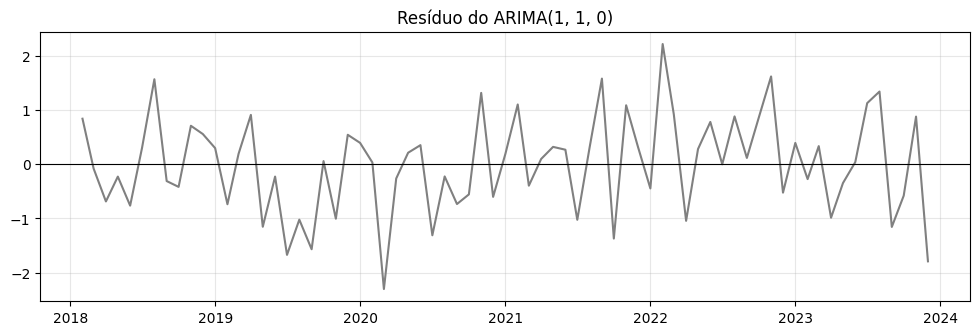

In [108]:
plt.figure(figsize=(12, 3.5))
plt.plot(residuo.index, residuo.values, color='gray')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Resíduo do ARIMA' + str(ordem_val))
plt.grid(alpha=0.3)
plt.show()

O resíduo oscila em torno de zero, sem tendência e sem padrão visível: o modelo capturou a estrutura da série.

## 🎯 Momento de praticar

Escolha o ARIMA para o **consumo industrial da planta B**, outra planta da mesma empresa, com as **duas estratégias** do item 3. Os passos:

1. Carregue o dataset, mostre o início e **plote** a série (o dado puro)
2. Calcule a **média semanal** (descarte a última semana, que está incompleta) e **plote** a série semanal e a sua diferença para escolher o $d$
3. Divida a série em **treino** (36 semanas), **validação** (8) e **teste** (8) e plote as três partes
4. **Validação:** ajuste os candidatos (busca em grade, $p$, $d$ e $q$ de 0 a 2) no treino, mostre o MAE na validação e escolha pela regra do item 3.2
5. **Teste:** reajuste o escolhido com treino e validação e compare com o Naive
6. **AIC e BIC:** ajuste a mesma grade em treino e validação juntos e mostre o melhor AIC e o melhor BIC para o $d$ da validação
7. **Compare** as duas estratégias no teste
8. Plote o **resíduo** do modelo escolhido pela validação

Para carregar o dataset, use:

```python
df_b = pd.read_csv(
    PATH + 'datasets/consumo_energia_planta_b.csv',
    parse_dates=['timestamp'],
    index_col='timestamp',
)
```

**Passo 1:** carregue o dataset, mostre o início e plote a série. A planta B tem uma medida **por hora**:

**Passo 2:** a média semanal, sem a última semana (incompleta), e a sua diferença.

**Passo 3:** o treino, a validação e o teste, em ordem no tempo.

**Passo 4:** a busca em grade no treino, com o MAE na validação. Usamos o dicionário `tendencia` do item 3.2.

**Passo 5:** o escolhido, reajustado com treino e validação, contra o Naive no teste.

**Passo 6:** o AIC e o BIC da mesma grade, ajustada em treino e validação juntos.

O AIC e o BIC escolhem só $p$ e $q$, com o $d$ escolhido pela validação (`ordem_val_b`).

**Passo 7:** as duas estratégias no teste, ao lado do Naive.

**Passo 8:** o resíduo do modelo escolhido pela validação.

**Conclusão:** a planta B tem só 52 semanas, e a validação de 8 semanas é curta e ruidosa.

* **Validação:** o ARIMA(1, 0, 0), com MAE de 9,92, é o único candidato dentro dos 10% (o Naive tem 87,87 na validação)
* **Teste:** o ARIMA(1, 0, 0) erra 57,59 (MAE), **pior que o Naive** (50,25): a escolha pela validação não se confirmou
* **AIC e BIC:** com o $d = 0$ da validação, os dois apontam o ARIMA(1, 0, 1), que erra 55,69 no teste, também **pior que o Naive**
* **Comparação:** nenhuma estratégia vence sempre, e é o teste que mostra se o modelo escolhido vale o uso

## 📌 5 - Previsão

A pergunta de negócio: **quanto produzir nos próximos 12 meses?** Primeiro prevemos o `teste` com o ARIMA(1, 1, 0) ajustado em `treino_val`, para conferir com os valores reais. No fim, reajustamos o modelo com a série inteira para prever o futuro. Estas são as variáveis que vamos usar:

In [109]:
print('Modelo escolhido (ordem_val): ARIMA' + str(ordem_val))
print('treino_val:', len(treino_val), 'meses | teste:', len(teste), 'meses | horizonte h:', h)

Modelo escolhido (ordem_val): ARIMA(1, 1, 0)
treino_val: 72 meses | teste: 12 meses | horizonte h: 12


### 5.1 - Previsão e integração

O `.forecast(h)` devolve os próximos $h$ valores, na escala original (milhares de unidades). Por dentro, cada mês é previsto **um por vez**: o mês 73 parte do último valor observado, e o mês 74 não tem dado novo, então parte da previsão anterior. O ARIMA prevê as **variações** (com um AR(1) na série diferenciada) e as **soma** ao último valor, que é a integração do item 1.2:

In [110]:
previsao = ajuste_val.forecast(h)
previsao.round(1).head()

,predicted_mean
2024-01-01,207.4
2024-02-01,208.2
2024-03-01,209.4
2024-04-01,210.6
2024-05-01,211.9


### 5.2 - Intervalo de previsão

A previsão **não é uma linha certa** para o futuro: é uma faixa onde o valor real deve cair. Essa faixa é o **intervalo de previsão**, que cobre os valores **futuros**. O `.get_forecast(h)` devolve um objeto com a previsão (`.predicted_mean`) e, em `.conf_int(alpha=...)`, os limites do intervalo (o nome do método usa "confiança", mas o intervalo calculado é o de previsão). O `alpha` é a probabilidade **fora** do intervalo: `alpha=0.2` dá um intervalo de 80% e `alpha=0.05` dá um de 95%:

In [111]:
previsao_ic = ajuste_val.get_forecast(h)
ic80 = previsao_ic.conf_int(alpha=0.2)
ic95 = previsao_ic.conf_int(alpha=0.05)

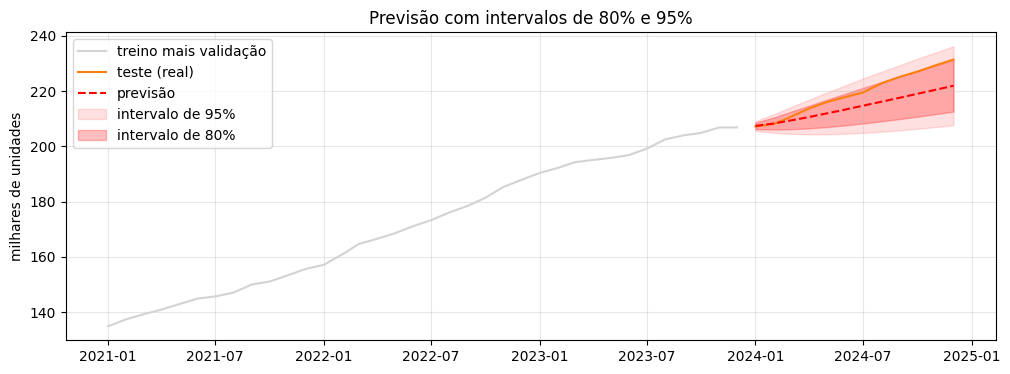

In [112]:
plt.figure(figsize=(12, 4))
plt.plot(treino_val.index[-36:], treino_val.values[-36:], color='lightgray', label='treino mais validação')
plt.plot(teste.index, teste.values, color='tab:orange', label='teste (real)')
plt.plot(previsao.index, previsao.values, color='red', linestyle='--', label='previsão')
plt.fill_between(ic95.index, ic95.iloc[:, 0], ic95.iloc[:, 1], color='red', alpha=0.12, label='intervalo de 95%')
plt.fill_between(ic80.index, ic80.iloc[:, 0], ic80.iloc[:, 1], color='red', alpha=0.25, label='intervalo de 80%')
plt.title('Previsão com intervalos de 80% e 95%')
plt.ylabel('milhares de unidades')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A faixa abre com o horizonte, e os 12 valores reais ficaram dentro do intervalo de 95%.

### 5.3 - Comparação com o baseline

O baseline (Naive) é a **régua**: um ARIMA só vale a pena se ganhar dele. No mesmo gráfico, o teste real, a previsão do ARIMA(1, 1, 0) e a do Naive (item 3.2):

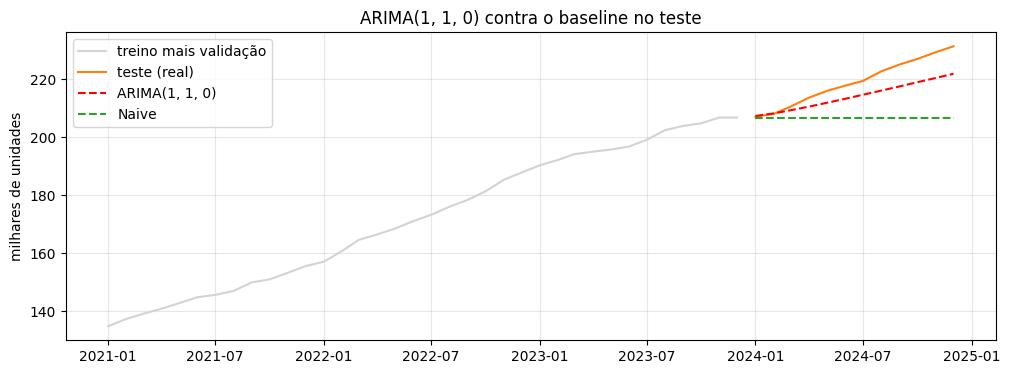

In [113]:
plt.figure(figsize=(12, 4))
plt.plot(treino_val.index[-36:], treino_val.values[-36:], color='lightgray', label='treino mais validação')
plt.plot(teste.index, teste.values, color='tab:orange', label='teste (real)')
plt.plot(previsao.index, previsao.values, color='red', linestyle='--', label='ARIMA' + str(ordem_val))
plt.plot(naive.index, naive.values, color='tab:green', linestyle='--', label='Naive')
plt.title('ARIMA(1, 1, 0) contra o baseline no teste')
plt.ylabel('milhares de unidades')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

O ARIMA(1, 1, 0) segue a tendência de alta, e o Naive fica parado no último valor. Os erros do item 3.2 confirmam: MAE de 4,90 contra 12,22 do Naive no teste, cerca de 60% menos erro. O ARIMA(1, 1, 0) **vence o baseline**.

> O AIC e o BIC avaliam o **ajuste**, e o MAE avalia a **previsão em dados não vistos**. São perguntas diferentes, e o teste é quem diz o desempenho. As métricas formais e a validação com várias janelas ficam para a Aula 6.

### 5.4 - Reajuste com a série inteira

Depois de escolher e avaliar, o modelo é **reajustado com a série inteira** (os 84 meses) para prever o futuro, os 12 meses seguintes. A métrica calculada na série inteira é **otimista**, porque o modelo já viu esses dados: o desempenho do modelo é o do teste. O `.get_forecast(h)` do modelo reajustado devolve a previsão e o intervalo de 95%:

O ARIMA, como visto, **não é sazonal** e não repete um padrão que se repete a cada ano: para séries com ciclos (como o consumo por dia da semana), o próximo passo é o **SARIMA**, na Aula 5.

## 🎯 Momento de praticar

Faça a sequência completa para a **demanda de uma segunda fábrica**, uma série artificial (96 meses, com a demanda subindo cerca de 2 por mês), com as duas estratégias. Os passos:

1. Gere a série (código abaixo) e plote a série e a sua diferença para escolher o $d$
2. Divida em **treino** (72 meses), **validação** (12) e **teste** (12)
3. **Validação:** a busca em grade ($p$, $d$ e $q$ de 0 a 2) no treino, o MAE na validação e a escolha pela regra do item 3.2
4. **AIC e BIC:** a mesma grade em treino e validação juntos, com o $d$ da validação
5. **Compare** as duas estratégias e o Naive no teste
6. Plote o **resíduo** do modelo escolhido pela validação
7. **Reajuste** o escolhido com a série inteira e preveja os 12 meses seguintes, com o intervalo de 95%

Para gerar a série, use:

```python
erro_d = np.random.default_rng(10).normal(0, 1, 97)
variacoes_d = 2.0 + erro_d[1:] + 0.7 * erro_d[:-1]
demanda_d = pd.Series(
    80 + np.cumsum(variacoes_d),
    index=pd.date_range('2016-01-01', periods=96, freq='MS'),
)
```

**Passo 1:** gere a série e plote a série e a sua diferença.

**Passo 2:** o treino, a validação e o teste.

**Passo 3:** a busca em grade no treino e a escolha pela validação.

**Passo 4:** o AIC e o BIC da mesma grade, ajustada em treino e validação juntos.

O AIC e o BIC escolhem só $p$ e $q$, com o $d$ escolhido pela validação (`ordem_val_d`).

**Passo 5:** as duas estratégias no teste, ao lado do Naive.

**Passo 6:** o resíduo do modelo escolhido pela validação.

**Passo 7:** o escolhido, reajustado com a série inteira, prevê os 12 meses seguintes com o intervalo de 95%.

**Conclusão:** a demanda da segunda fábrica sobe com o tempo.

* **Validação:** o ARIMA(1, 1, 0), com MAE de 0,66, empatado com o (1, 2, 1) e o (0, 2, 1), mas mais simples, contra 9,86 do Naive na validação
* **Teste:** o ARIMA(1, 1, 0) erra 4,64 (MAE), contra 13,98 do Naive: ganha do baseline
* **AIC e BIC:** com o $d = 1$ da validação, os dois apontam o ARIMA(0, 1, 1) (AIC de 197,3 e BIC de 204,5), que erra 4,37 no teste, um pouco menos que o escolhido pela validação
* **Previsão:** reajustado com os 96 meses, o modelo prevê os próximos 12 meses com um intervalo de 95% que abre com o horizonte

## 📌 Conclusão

* A **diferenciação** (`.diff()`) remove a tendência e a **integração** (`.cumsum()`) volta à escala original. Diferencie até a série ficar estacionária e pare
* **ARIMA($p$, $d$, $q$)** = AR($p$) + I($d$) + MA($q$). Com $d \geq 1$, a deriva entra com `trend='t'`
* A **busca em grade** testa combinações de $p$, $d$ e $q$. A **validação temporal** escolhe pelo menor MAE ou RMSE (métrica definida antes; erro parecido, o mais simples; precisa ganhar do **baseline**), e o **teste** mede o resultado final uma única vez
* O **AIC e o BIC** são a outra forma de selecionar: o `ARIMA` os calcula automaticamente no ajuste, sem partição de validação, e comparam $p$ e $q$ com o $d$ da validação. Eles medem o ajuste com penalização (não o erro de previsão). Servem para filtrar candidatos ou séries curtas, e um AIC menor **não garante** o menor erro no teste
* O **resíduo** deve parecer ruído: confira o gráfico do resíduo
* A previsão vem com um **intervalo de previsão** que abre com o horizonte, e o modelo escolhido é **reajustado com a série inteira** para prever o futuro
* O ARIMA é **não sazonal**: é o assunto da Aula 5 (SARIMA)